In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

midfielders = pd.read_csv(
    "data\processed\midfielders_analysis_ready.csv"
)

forwards = pd.read_csv(
    "data\processed\ forwards_analysis_ready.csv"
)

defenders = pd.read_csv(
    "data\processed\defenders_analysis_ready.csv"
)


<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:16: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:16: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\1167321009.py:12: SyntaxWarning: invalid escape sequence '\p'
  "data\processed\midfielders_analysis_ready.csv"
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\1167321009.py:16: SyntaxWarning: invalid escape sequence '\p'
  "data\processed\ forwards_analysis_ready.csv"
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\1167321009.py:20: SyntaxWarning: invalid escape sequence '\p'
  "data\processed\defenders_analysis_ready.csv"
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\1167321009.py:11: DtypeWarning: Columns (0: weak_foot) have mixed types. Specify dtype option on import or set low_memory=False.
  midfielders = pd.read_csv(


In [29]:
midfielder_features = [
    #Scoring
    "goals_per90",
    "xg_per90",

    #Chance Creation
    "assists_per90",
    "xag_per90",
    "per_90_minutes_kp",
    "sca_sca90",

    #Progression
    "per_90_minutes_prgp",
    "per_90_minutes_prgc",
    "per_90_minutes_1_per_3",
    "per_90_minutes_ppa",


    #Possession/passing
    "pass_completion_pct",

    #Defense
    "per_90_minutes_tackles_tkl",
    "per_90_minutes_int"

]

forward_features = [
    # Scoring
    "goals_per90",
    "xg_per90",

    # Chance Creation
    "assists_per90",
    "xag_per90",
    "per_90_minutes_kp",
    "sca_sca90",

    # Progression / Attacking
    "per_90_minutes_prgc",
    "per_90_minutes_ppa",

    # Possession
    "pass_completion_pct",

    # Defensive Work
    "per_90_minutes_tackles_tkl",
    "per_90_minutes_int"
]

defender_features = [
    # Defensive Contribution
    "per_90_minutes_tackles_tkl",
    "per_90_minutes_int",

    # Passing
    "pass_completion_pct",

    # Progression
    "per_90_minutes_prgp",
    "per_90_minutes_prgc",
    "per_90_minutes_1_per_3",

    # Attacking Contribution
    "assists_per90",
    "xag_per90",
    "per_90_minutes_kp",

    # Optional scoring contribution
    "goals_per90",
    "xg_per90"
]

POSITION_FEATURES = {
    "Midfielder": midfielder_features,
    "Forward": forward_features,
    "Defender": defender_features
}

POSITION_DATA = {
    "Midfielder": midfielders,
    "Forward": forwards,
    "Defender": defenders
}

X_by_position = {
    position: POSITION_DATA[position][features].copy()
    for position, features in POSITION_FEATURES.items()
}

X_midfielders = midfielders[
    midfielder_features
].copy()

X_forwards = forwards[
    forward_features
].copy()

X_defenders = defenders[
    defender_features
].copy()

feature_sets = {
    "Midfielder": X_midfielders,
    "Forward": X_forwards,
    "Defender": X_defenders
}

for position, X_pos in feature_sets.items():

    # Replace infinity values with NaN
    X_pos = X_pos.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Save cleaned version back
    feature_sets[position] = X_pos

    print(f"\n===== {position} =====")

    print("Shape:", X_pos.shape)

    print("\nMissing counts:")
    print(
        X_pos
        .isnull()
        .sum()
        .sort_values(ascending=False)
    )

    missing_pct = (
        X_pos
        .isnull()
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print("\nMissing percentages:")
    print(
        missing_pct[
            missing_pct > 0
        ].round(2)
    )

X_midfielders = feature_sets["Midfielder"]
X_forwards = feature_sets["Forward"]
X_defenders = feature_sets["Defender"]



===== Midfielder =====
Shape: (7874, 13)

Missing counts:
per_90_minutes_kp             1252
per_90_minutes_ppa            1252
per_90_minutes_1_per_3        1252
per_90_minutes_prgc           1252
per_90_minutes_prgp           1252
per_90_minutes_tackles_tkl    1252
pass_completion_pct           1250
xg_per90                      1249
xag_per90                     1249
sca_sca90                     1249
per_90_minutes_int               5
assists_per90                    0
goals_per90                      0
dtype: int64

Missing percentages:
per_90_minutes_kp             15.90
per_90_minutes_ppa            15.90
per_90_minutes_1_per_3        15.90
per_90_minutes_prgc           15.90
per_90_minutes_prgp           15.90
per_90_minutes_tackles_tkl    15.90
pass_completion_pct           15.88
xg_per90                      15.86
xag_per90                     15.86
sca_sca90                     15.86
per_90_minutes_int             0.06
dtype: float64

===== Forward =====
Shape: (5723, 11)



In [30]:
imputed_sets = {}
imputers = {}

for position, X_pos in feature_sets.items():

    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(
        X_pos
    )

    imputers[position] = imputer
    imputed_sets[position] = X_imputed

    print(f"\n===== {position} =====")

    print(
        "NaN values:",
        np.isnan(X_imputed).sum()
    )

    print(
        "Infinite values:",
        np.isinf(X_imputed).sum()
    )

    print(
        "Shape:",
        X_imputed.shape
    )


===== Midfielder =====
NaN values: 0
Infinite values: 0
Shape: (7874, 13)

===== Forward =====
NaN values: 0
Infinite values: 0
Shape: (5723, 11)

===== Defender =====
NaN values: 0
Infinite values: 0
Shape: (9525, 11)


In [31]:
scaled_sets = {}
scalers = {}

for position, X_imputed in imputed_sets.items():

    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(
        X_imputed
    )

    scalers[position] = scaler
    scaled_sets[position] = X_scaled

    print(f"\n===== {position} =====")

    print(
        "Shape:",
        X_scaled.shape
    )

    print("Mean:")
    print(
        X_scaled.mean(axis=0)
    )

    print("Standard deviation:")
    print(
        X_scaled.std(axis=0)
    )

X_midfielders_scaled = scaled_sets["Midfielder"]
X_forwards_scaled = scaled_sets["Forward"]
X_defenders_scaled = scaled_sets["Defender"]

midfielder_scaler = scalers["Midfielder"]
forward_scaler = scalers["Forward"]
defender_scaler = scalers["Defender"]


===== Midfielder =====
Shape: (7874, 13)
Mean:
[-9.92630187e-17 -6.85817220e-17 -5.68506380e-17  1.08286930e-17
 -3.51932521e-16 -4.25928589e-16  2.89667536e-16  5.59482469e-17
  2.56279066e-16  2.30109725e-17  1.73710283e-15  1.21371600e-16
 -1.31749098e-16]
Standard deviation:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

===== Forward =====
Shape: (5723, 11)
Mean:
[-5.95947079e-17  1.03049182e-16  8.69089490e-18  1.53642606e-16
 -2.65693073e-16  5.29523811e-16 -1.12981634e-16  4.34544745e-17
 -9.93245131e-18 -3.87986379e-17  7.20102720e-17]
Standard deviation:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

===== Defender =====
Shape: (9525, 11)
Mean:
[ 2.26776894e-16  3.50609014e-16  2.05889549e-16  2.25284941e-16
 -1.19356260e-16  2.11857362e-16  5.66942235e-17  1.55163138e-16
 -1.34275793e-16  2.08873455e-17  2.98390650e-17]
Standard deviation:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [32]:
k_values = range(2, 11)

clustering_results = {}

for position, X_scaled in scaled_sets.items():

    print(f"\n===== {position} =====")

    silhouette_scores = []
    davies_scores = []
    inertias = []

    for k in k_values:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = kmeans.fit_predict(
            X_scaled
        )

        silhouette = silhouette_score(
            X_scaled,
            labels
        )

        davies = davies_bouldin_score(
            X_scaled,
            labels
        )

        silhouette_scores.append(
            silhouette
        )

        davies_scores.append(
            davies
        )

        inertias.append(
            kmeans.inertia_
        )

        print(
            f"k={k} | "
            f"Silhouette={silhouette:.3f} | "
            f"Davies-Bouldin={davies:.3f}"
        )

    clustering_results[position] = {
        "k_values": list(k_values),
        "silhouette_scores": silhouette_scores,
        "davies_scores": davies_scores,
        "inertias": inertias
    }


===== Midfielder =====
k=2 | Silhouette=0.306 | Davies-Bouldin=1.492
k=3 | Silhouette=0.174 | Davies-Bouldin=1.725
k=4 | Silhouette=0.177 | Davies-Bouldin=1.565
k=5 | Silhouette=0.147 | Davies-Bouldin=1.751
k=6 | Silhouette=0.133 | Davies-Bouldin=1.783
k=7 | Silhouette=0.136 | Davies-Bouldin=1.827
k=8 | Silhouette=0.138 | Davies-Bouldin=1.813
k=9 | Silhouette=0.136 | Davies-Bouldin=1.813
k=10 | Silhouette=0.117 | Davies-Bouldin=1.797

===== Forward =====
k=2 | Silhouette=0.275 | Davies-Bouldin=1.522
k=3 | Silhouette=0.186 | Davies-Bouldin=1.679
k=4 | Silhouette=0.158 | Davies-Bouldin=1.677
k=5 | Silhouette=0.143 | Davies-Bouldin=1.734
k=6 | Silhouette=0.129 | Davies-Bouldin=1.795
k=7 | Silhouette=0.125 | Davies-Bouldin=1.747
k=8 | Silhouette=0.118 | Davies-Bouldin=1.774
k=9 | Silhouette=0.113 | Davies-Bouldin=1.831
k=10 | Silhouette=0.112 | Davies-Bouldin=1.944

===== Defender =====
k=2 | Silhouette=0.278 | Davies-Bouldin=1.672
k=3 | Silhouette=0.204 | Davies-Bouldin=1.680
k=4 | Silho

In [33]:
best_k_by_position = {}

for position, results in clustering_results.items():

    best_index = np.argmax(
        results["silhouette_scores"]
    )

    best_k = results[
        "k_values"
    ][best_index]

    best_k_by_position[
        position
    ] = best_k

    print(
        f"{position}: "
        f"best k = {best_k}"
    )

Midfielder: best k = 2
Forward: best k = 2
Defender: best k = 2


In [34]:
position_data = {
    "Midfielder": midfielders,
    "Forward": forwards,
    "Defender": defenders
}

final_models = {}
cluster_centers_by_position = {}

for position, X_scaled in scaled_sets.items():

    best_k = best_k_by_position[position]

    kmeans = KMeans(
        n_clusters=best_k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    # Add cluster labels to the correct dataframe
    position_data[position]["cluster"] = labels

    # Store model
    final_models[position] = kmeans

    # Convert cluster centers back into a DataFrame
    cluster_centers_by_position[position] = pd.DataFrame(
        kmeans.cluster_centers_,
        columns=POSITION_FEATURES[position]
    )

C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\3561780666.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  position_data[position]["cluster"] = labels
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\3561780666.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  position_data[position]["cluster"] = labels
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\3561780666.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Con

In [35]:
DISPLAY_COLUMNS = {

    "Midfielder": [
        "player",
        "team",
        "season",
        "player_positions",
        "goals_per90",
        "assists_per90",
        "xag_per90",
        "per_90_minutes_prgp"
    ],

    "Forward": [
        "player",
        "team",
        "season",
        "player_positions",
        "goals_per90",
        "xg_per90",
        "assists_per90",
        "xag_per90"
    ],

    "Defender": [
        "player",
        "team",
        "season",
        "player_positions",
        "per_90_minutes_tackles_tkl",
        "per_90_minutes_int",
        "pass_completion_pct",
        "per_90_minutes_prgp"
    ]
}

for position, dataframe in position_data.items():

    best_k = best_k_by_position[position]

    cluster_centers = (
        cluster_centers_by_position[position]
    )

    print(
        f"\n\n========== {position} =========="
    )

    for cluster in range(best_k):

        print(
            f"\n==== Cluster {cluster} ===="
        )

        sample = (
            dataframe[
                dataframe["cluster"] == cluster
            ][
                DISPLAY_COLUMNS[position]
            ]
            .head(20)
        )

        print(sample)

        profile = (
            cluster_centers
            .iloc[cluster]
            .sort_values(
                ascending=False
            )
        )

        print("\nHighest features:")
        print(
            profile.head(6)
        )

        print("\nLowest features:")
        print(
            profile.tail(6)
        )



========== Midfielder ==========

==== Cluster 0 ====
                 player          team  season player_positions  goals_per90  \
0       Aaron Boupendza     Hatayspor    2021               ST         0.79   
2          Aaron Lennon       Burnley    1718               RM         0.00   
3          Aaron Lennon       Burnley    1819           RM, LM         0.07   
4          Aaron Lennon       Burnley    1920           RM, LM         0.00   
5          Aaron Lennon       Burnley    2122           RM, LM         0.12   
6          Aaron Lennon   Kayserispor    2021           RM, LM         0.00   
10         Aaron Ramsey       Burnley    2324      LM, CM, CAM         0.00   
13         Aaron Ramsey          Nice    2223          CM, CAM         0.06   
14       Aaron Tshibola  Waas-Beveren    1920               CM         0.00   
15    Aatif Chahechouhe   Antalyaspor    1920          LM, CAM         0.08   
16    Aatif Chahechouhe    Erzurum BB    2021          CAM, LM         0.28

In [36]:
position = "Forward"

cluster_centers = cluster_centers_by_position[position]
best_k = best_k_by_position[position]

for cluster in range(best_k):

    print(f"\n===== Forward Cluster {cluster} =====")

    profile = (
        cluster_centers
        .iloc[cluster]
        .sort_values(ascending=False)
    )

    print("\nHighest features:")
    print(profile.head(6))

    print("\nLowest features:")
    print(profile.tail(6))


===== Forward Cluster 0 =====

Highest features:
xg_per90                      0.105061
goals_per90                   0.049948
per_90_minutes_tackles_tkl   -0.176833
per_90_minutes_int           -0.182284
pass_completion_pct          -0.188872
assists_per90                -0.320259
Name: 0, dtype: float64

Lowest features:
assists_per90         -0.320259
per_90_minutes_prgc   -0.422119
xag_per90             -0.432441
per_90_minutes_ppa    -0.460462
per_90_minutes_kp     -0.470656
sca_sca90             -0.472328
Name: 0, dtype: float64

===== Forward Cluster 1 =====

Highest features:
sca_sca90              1.084776
per_90_minutes_kp      1.080935
per_90_minutes_ppa     1.057524
xag_per90              0.993169
per_90_minutes_prgc    0.969463
assists_per90          0.735525
Name: 1, dtype: float64

Lowest features:
assists_per90                 0.735525
pass_completion_pct           0.433774
per_90_minutes_int            0.418645
per_90_minutes_tackles_tkl    0.406126
goals_per90       

In [37]:
position = "Defender"

cluster_centers = cluster_centers_by_position[position]
best_k = best_k_by_position[position]

for cluster in range(best_k):

    print(f"\n===== Defender Cluster {cluster} =====")

    profile = (
        cluster_centers
        .iloc[cluster]
        .sort_values(ascending=False)
    )

    print("\nHighest features:")
    print(profile.head(6))

    print("\nLowest features:")
    print(profile.tail(6))


===== Defender Cluster 0 =====

Highest features:
per_90_minutes_kp             1.216449
xag_per90                     1.182323
per_90_minutes_prgc           1.106788
assists_per90                 0.912915
per_90_minutes_tackles_tkl    0.521401
per_90_minutes_prgp           0.519172
Name: 0, dtype: float64

Lowest features:
per_90_minutes_prgp       0.519172
xg_per90                  0.278628
goals_per90               0.230205
per_90_minutes_1_per_3    0.219507
per_90_minutes_int       -0.248185
pass_completion_pct      -0.554101
Name: 0, dtype: float64

===== Defender Cluster 1 =====

Highest features:
pass_completion_pct       0.221820
per_90_minutes_int        0.099354
per_90_minutes_1_per_3   -0.087874
goals_per90              -0.092157
xg_per90                 -0.111541
per_90_minutes_prgp      -0.207837
Name: 1, dtype: float64

Lowest features:
per_90_minutes_prgp          -0.207837
per_90_minutes_tackles_tkl   -0.208729
assists_per90                -0.365461
per_90_minutes_prgc

In [38]:
pca_models = {}
pca_results = {}

for position, X_scaled in scaled_sets.items():

    pca = PCA(n_components=2)

    X_pca = pca.fit_transform(
        X_scaled
    )

    # Store PCA model and transformed data
    pca_models[position] = pca
    pca_results[position] = X_pca

    # Add PCA columns to the correct dataframe
    position_data[position]["PC1"] = X_pca[:, 0]
    position_data[position]["PC2"] = X_pca[:, 1]

    print(f"\n===== {position} =====")

    print("Explained variance:")
    print(
        pca.explained_variance_ratio_
    )

    print(
        "Total explained variance:",
        pca.explained_variance_ratio_.sum()
    )


===== Midfielder =====
Explained variance:
[0.42673151 0.1924166 ]
Total explained variance: 0.6191481138188906

===== Forward =====
Explained variance:
[0.40325424 0.20499673]
Total explained variance: 0.6082509696021239

===== Defender =====
Explained variance:
[0.32499505 0.17148116]
Total explained variance: 0.49647621283908716


C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\992748591.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  position_data[position]["PC1"] = X_pca[:, 0]
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\992748591.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  position_data[position]["PC2"] = X_pca[:, 1]
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\992748591.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Cons

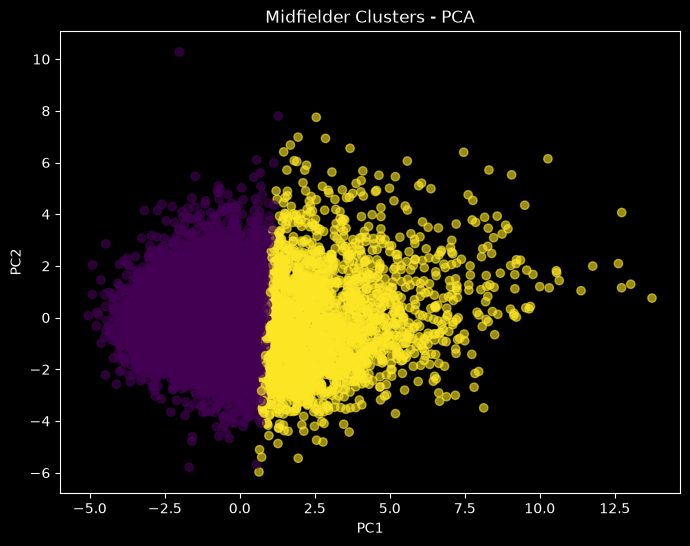

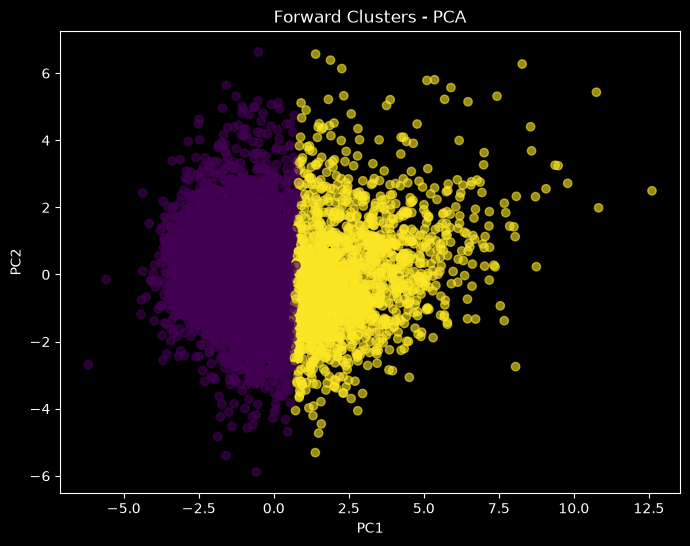

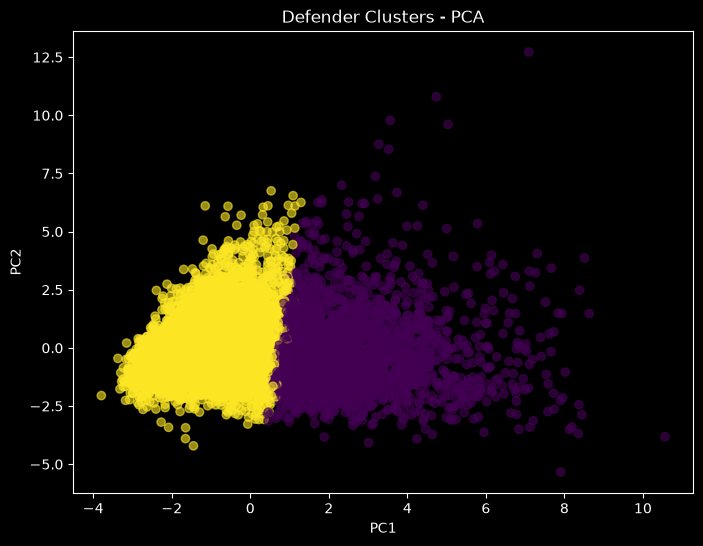

In [39]:
for position, dataframe in position_data.items():

    plt.figure(figsize=(8, 6))

    plt.scatter(
        dataframe["PC1"],
        dataframe["PC2"],
        c=dataframe["cluster"],
        alpha=0.6
    )

    plt.xlabel("PC1")
    plt.ylabel("PC2")

    plt.title(
        f"{position} Clusters - PCA"
    )

    plt.show()

In [40]:
CLUSTER_NAMES = {
    "Midfielder": {
        0: "Defensive / Holding Midfielder",
        1: "Creative / Progressive Midfielder"
    },

    "Forward": {
        0: "Direct / Finishing Forward",
        1: "Creative / Progressive Forward"
    },

    "Defender": {
        0: "Attacking / Progressive Defender",
        1: "Defensive / Central Defender"
    }
}

for position, dataframe in position_data.items():

    if position not in CLUSTER_NAMES:
        continue

    if not CLUSTER_NAMES[position]:
        continue

    dataframe["archetype"] = (
        dataframe["cluster"]
        .map(CLUSTER_NAMES[position])
    )

    print(
        f"\n===== {position} ====="
    )

    print(
        dataframe[
            [
                "player",
                "team",
                "player_positions",
                "cluster",
                "archetype"
            ]
        ].head(30)
    )




===== Midfielder =====
                   player           team player_positions  cluster  \
0         Aaron Boupendza      Hatayspor               ST        0   
1             Aaron Kovar           LAFC           RM, LM        1   
2            Aaron Lennon        Burnley               RM        0   
3            Aaron Lennon        Burnley           RM, LM        0   
4            Aaron Lennon        Burnley           RM, LM        0   
5            Aaron Lennon        Burnley           RM, LM        0   
6            Aaron Lennon    Kayserispor           RM, LM        0   
7              Aaron Mooy       Brighton          CM, CDM        1   
8            Aaron Ramsey        Arsenal      CM, CDM, RM        1   
9            Aaron Ramsey        Arsenal     CM, CDM, CAM        1   
10           Aaron Ramsey        Burnley      LM, CM, CAM        0   
11           Aaron Ramsey       Juventus          CM, CAM        1   
12           Aaron Ramsey       Juventus          CM, CAM        1

C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\2595310052.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe["archetype"] = (
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\2595310052.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataframe["archetype"] = (
C:\Users\Titus\AppData\Local\Temp\ipykernel_12388\2595310052.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once 

In [41]:
#cluster_centers.to_csv("midfielder_cluster_centers.csv", index=True)
#midfielders.to_csv("midfielders_clustered.csv", index=False)

for position, dataframe in position_data.items():

    filename = (
        f"data/processed/ "
        f"{position.lower()}s_clustered.csv"
    )

    dataframe.to_csv(
        filename,
        index=False
    )

    print(
        f"Saved {position}: {filename}"
    )


Saved Midfielder: data/processed/ midfielders_clustered.csv
Saved Forward: data/processed/ forwards_clustered.csv
Saved Defender: data/processed/ defenders_clustered.csv
